# ESS Battery Health 

데이터셋 : Stanford & MIT - *Data-driven prediction of battery cycle life before capacity degradation* (Nature Energy, 2019)  

## 라이브러리 및 시각화 설정

필요한 라이브러리를 불러오고 그래프의 기본 크기와 글자 크기를 설정한다.

In [44]:
import os
import warnings
from importlib.util import find_spec

import h5py
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import mat73                      # MATLAB v7.3 (HDF5) 형식 로드용
import numpy as np
import pandas as pd
import scipy.io as sio            # MATLAB v7.2 이하 형식 로드용 (fallback)
from IPython.display import display
from scipy.stats import theilslopes

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12


## 데이터 파일 확인

데이터 경로, 파일 목록과 크기를 확인한다.

In [45]:
# 데이터 경로 설정
PROJECT_DIR = os.path.abspath(os.getcwd())
if os.path.basename(PROJECT_DIR) == "notebooks":
    PROJECT_DIR = os.path.dirname(PROJECT_DIR)
DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError("프로젝트 루트 또는 notebooks 폴더에서 실행하고 data/raw를 확인하세요.")

files = sorted(os.listdir(DATA_DIR))
print(f"데이터 경로 : {DATA_DIR}")
print(f"파일 목록 :")
for f in files:
    size_mb = os.path.getsize(os.path.join(DATA_DIR, f)) / (1024**3)
    print(f"   {f}  ({size_mb:.1f} GB)")

데이터 경로 : /Users/kim-youngjun/ess-battery-project/data/raw
파일 목록 :
   2017-05-12_batchdata_updated_struct_errorcorrect.mat  (2.8 GB)
   2018-02-20_batchdata_updated_struct_errorcorrect.mat  (1.9 GB)
   2018-04-12_batchdata_updated_struct_errorcorrect.mat  (3.0 GB)


## Batch 1 데이터 불러오기

MATLAB 파일을 불러오고 최상위 키를 확인한다.

In [46]:
# Batch 1 로드 (가장 많이 사용되는 기본 배치)
batch1_path = os.path.join(DATA_DIR, '2017-05-12_batchdata_updated_struct_errorcorrect.mat')

def load_mat(path):
    """
    .mat 파일 로더 (버전 자동 감지)
    - MATLAB v7.3 (HDF5, 대용량) : mat73.loadmat() 사용
    - MATLAB v7.2 이하          : scipy.io.loadmat() 사용
    """
    try:
        data = mat73.loadmat(path)
        print("로드 완료 (MATLAB v7.3 / HDF5 형식)")
    except Exception:
        data = sio.loadmat(path, simplify_cells=True)
        print("로드 완료 (MATLAB v7.2 이하 형식)")
    return data

print("로딩 중... (파일이 크므로 수십 초 소요될 수 있습니다)")
mat = load_mat(batch1_path)

# 최상위 키 확인
print(f"\n최상위 키 : {list(mat.keys())}")

ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:root:ERROR: MATLAB type not supported: string, (uint32)
ERROR:ro

로딩 중... (파일이 크므로 수십 초 소요될 수 있습니다)
로드 완료 (MATLAB v7.3 / HDF5 형식)

최상위 키 : ['batch', 'batch_date']


## 배터리 셀 구조 확인

배터리 셀 수, 자료형과 필드 목록을 확인한다.

In [47]:
batch = mat['batch']

# mat73은 list of dict, scipy는 structured array로 반환
# 아래 코드로 둘 다 동일하게 처리
if isinstance(batch, dict):
    # mat73: {'field': [val0, val1, ...]} 형태 → list of dict로 변환
    keys = list(batch.keys())
    n_cells = len(batch[keys[0]])
    batch = [{k: batch[k][i] for k in keys} for i in range(n_cells)]
    print("mat73 형식 → list of dict 변환 완료")

print(f"배터리 셀 수    : {len(batch)}")
print(f"타입            : {type(batch)}")
print(f"첫 번째 셀 키   : {list(batch[0].keys())}")

mat73 형식 → list of dict 변환 완료
배터리 셀 수    : 46
타입            : <class 'list'>
첫 번째 셀 키   : ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']


## 개별 셀 구조 확인

첫 번째 배터리 셀의 필드별 자료형과 배열 크기를 확인한다.

In [48]:
# 단일 셀 구조 상세 확인
cell0 = batch[0]

print("=" * 55)
print("배터리 셀[0] 구조")
print("=" * 55)

for key, val in cell0.items():
    if isinstance(val, np.ndarray):
        print(f"  {key:25s} | ndarray  | shape={val.shape}")
    elif isinstance(val, dict):
        print(f"  {key:25s} | dict     | keys={list(val.keys())}")
    else:
        print(f"  {key:25s} | {type(val).__name__:8s} | {val}")

배터리 셀[0] 구조
  Vdlin                     | ndarray  | shape=(1000,)
  barcode                   | NoneType | None
  channel_id                | NoneType | None
  cycle_life                | ndarray  | shape=()
  cycles                    | dict     | keys=['I', 'Qc', 'Qd', 'Qdlin', 'T', 'Tdlin', 'V', 'discharge_dQdV', 't']
  policy                    | str      | 3_6C-80PER_3_6C
  policy_readable           | str      | 3.6C(80%)-3.6C
  summary                   | dict     | keys=['IR', 'QCharge', 'QDischarge', 'Tavg', 'Tmax', 'Tmin', 'chargetime', 'cycle']


## 사이클 데이터 구조 확인

첫 번째 셀의 사이클 수와 사이클 내부 변수의 구조를 확인한다.

In [49]:
# cycles 내부 구조 확인 (핵심 시계열 데이터)
cycles_raw = cell0['cycles']

# mat73: cycles도 dict of lists 형태로 반환 → list of dict로 변환
if isinstance(cycles_raw, dict):
    keys = list(cycles_raw.keys())
    n_cycles = len(cycles_raw[keys[0]])
    cycles = [{k: cycles_raw[k][i] for k in keys} for i in range(n_cycles)]
    print(f"mat73 형식 → list of dict 변환 완료")
else:
    cycles = cycles_raw

print(f"총 사이클 수 : {len(cycles)}")
print(f"\n사이클[0] 내 변수 목록 :")
for key, val in cycles[0].items():
    if isinstance(val, np.ndarray):
        print(f"  {key:15s} | ndarray | shape={val.shape} | dtype={val.dtype}")
    else:
        print(f"  {key:15s} | {type(val).__name__:8s} | {val}")

mat73 형식 → list of dict 변환 완료
총 사이클 수 : 1189

사이클[0] 내 변수 목록 :
  I               | NoneType | None
  Qc              | NoneType | None
  Qd              | NoneType | None
  Qdlin           | NoneType | None
  T               | NoneType | None
  Tdlin           | NoneType | None
  V               | NoneType | None
  discharge_dQdV  | NoneType | None
  t               | NoneType | None


## 사이클별 요약 데이터 구성

각 배터리 셀의 summary 데이터를 추출하여 DataFrame으로 정리한다.

In [50]:
def to_list_of_dicts(d):
    """mat73의 dict-of-lists 구조를 list-of-dicts로 변환"""
    if isinstance(d, dict):
        keys = list(d.keys())
        n = len(d[keys[0]])
        return [{k: d[k][i] for k in keys} for i in range(n)]
    return d  # 이미 list 형태면 그대로 반환

def extract_summary(batch):
    """모든 배터리 셀의 summary 데이터를 DataFrame으로 변환"""
    records = []
    for i, cell in enumerate(batch):
        summary = cell['summary']
        # mat73은 summary도 dict-of-lists → 각 필드를 직접 접근
        if isinstance(summary, dict):
            qd   = np.array(summary['QDischarge'])
            qc   = np.array(summary['QCharge'])
            ir   = np.array(summary['IR'])
            tmax = np.array(summary['Tmax'])
            tavg = np.array(summary['Tavg'])
            tmin = np.array(summary['Tmin'])
            ct   = np.array(summary['chargetime'])
        else:
            qd   = summary['QDischarge']
            qc   = summary['QCharge']
            ir   = summary['IR']
            tmax = summary['Tmax']
            tavg = summary['Tavg']
            tmin = summary['Tmin']
            ct   = summary['chargetime']

        cycle_life = int(cell['cycle_life'])
        policy     = str(cell.get('policy_readable') or cell.get('policy') or 'unknown')
        n          = len(qd)

        for c in range(n):
            records.append({
                'cell_id'         : i,
                'cycle'           : c + 1,
                'cycle_life'      : cycle_life,
                'charging_policy' : policy,
                'QD'              : qd[c],
                'QC'              : qc[c],
                'IR'              : ir[c],
                'Tmax'            : tmax[c],
                'Tavg'            : tavg[c],
                'Tmin'            : tmin[c],
                'chargetime'      : ct[c],
            })
    return pd.DataFrame(records)

In [51]:
df = extract_summary(batch)

print(f"DataFrame shape : {df.shape}")
df.head()

DataFrame shape : (38811, 11)


,cell_id,cycle,cycle_life,charging_policy,QD,QC,IR,Tmax,Tavg,Tmin,chargetime
0,0,1,1190,3.6C(80%)-3.6C,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0,2,1190,3.6C(80%)-3.6C,1.070689,1.071042,0.016742,35.652016,31.875011,29.566130,13.341250
2,0,3,1190,3.6C(80%)-3.6C,1.071900,1.071674,0.016724,35.692978,31.931490,29.604385,13.425777
3,0,4,1190,3.6C(80%)-3.6C,1.072510,1.072304,0.016681,35.680588,31.932603,29.744202,13.425167
4,0,5,1190,3.6C(80%)-3.6C,1.073174,1.072970,0.016662,35.728691,31.959322,29.644709,13.341442


## 기본 통계 확인

수치형 열의 분포와 값의 범위를 확인한다.


이 표는 사이클 행 단위의 자료 점검용이다. 동일 셀의 수명이 반복되므로 여기의 cycle_life 평균을 셀별 평균 수명으로 해석하지 않는다. 셀별 수명 통계는 아래 배치별 수명 요약에서 계산한다.


In [52]:
# 기본 통계
df.describe().round(3)

,cell_id,cycle,cycle_life,QD,QC,IR,Tmax,Tavg,Tmin,chargetime
count,38811.000,38811.000,38811.000,38811.000,38811.000,38811.000,38811.000,38811.000,38811.000,38811.000
mean,20.771,442.121,884.241,1.045,1.045,0.017,37.322,33.404,30.589,11.510
std,13.469,276.876,186.940,0.059,0.061,0.001,2.760,1.964,1.575,4.518
min,0.000,1.000,534.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,9.000,211.000,731.000,1.036,1.036,0.017,35.961,32.438,29.938,10.653
50%,21.000,422.000,870.000,1.063,1.062,0.017,37.599,33.471,30.390,11.208
75%,32.000,640.000,1017.000,1.076,1.076,0.017,39.107,34.472,31.200,12.092
max,45.000,1226.000,1227.000,2.884,2.966,0.022,43.419,38.414,34.851,419.873


## 결측치 확인

열별 결측치 수를 확인한다.

In [53]:
print("결측치 현황 : ")
print(df.isnull().sum())

결측치 현황 : 
cell_id            0
cycle              0
cycle_life         0
charging_policy    0
QD                 0
QC                 0
IR                 0
Tmax               0
Tavg               0
Tmin               0
chargetime         0
dtype: int64


## 셀 및 충전 프로토콜 수 확인

고유 배터리 셀 수와 충전 프로토콜 종류 수를 확인한다.

In [54]:
print(f"\n배터리 셀 수   : {df['cell_id'].nunique()}")
print(f"충전 정책 종류 : {df['charging_policy'].nunique()}")


배터리 셀 수   : 46
충전 정책 종류 : 23


## 빈 초기 기록 제외

첫 사이클의 주요 측정값이 모두 0인 행을 제외한다.

In [55]:
measurement_cols = [
    "QD", "QC", "IR", "Tmax", "Tavg", "Tmin", "chargetime"
]

empty_mask = (
    df["cycle"].eq(1)
    & df[measurement_cols].eq(0).all(axis=1)
)

df_clean = df.loc[~empty_mask].copy()

print("제외한 행 수:", empty_mask.sum())
print("남은 행 수:", len(df_clean))
print("배터리 셀 수:", df_clean["cell_id"].nunique())

제외한 행 수: 46
남은 행 수: 38765
배터리 셀 수: 46


## 배치별 수명 요약

세 배치의 셀별 수명을 추출하고 배치별 기본 통계를 비교한다.

In [56]:
batch_files = {
    "Batch 1": "2017-05-12_batchdata_updated_struct_errorcorrect.mat",
    "Batch 2": "2018-02-20_batchdata_updated_struct_errorcorrect.mat",
    "Batch 3": "2018-04-12_batchdata_updated_struct_errorcorrect.mat",
}

records = []

for batch_name, filename in batch_files.items():
    with h5py.File(os.path.join(DATA_DIR, filename), "r") as f:
        life_refs = f["batch"]["cycle_life"][()].ravel()

        for i, ref in enumerate(life_refs):
            records.append({
                "batch": batch_name,
                "cell_id": i,
                "cycle_life": float(np.asarray(f[ref][()]).item()),
            })

df_life = pd.DataFrame(records)

life_stats = df_life.groupby("batch")["cycle_life"].agg(
    ["count", "min", "median", "mean", "max"]
).round(1)
display(life_stats)


,count,min,median,mean,max
batch,,,,,
Batch 1,46,534.0,858.5,844.7,1227.0
Batch 2,39,392.0,472.0,565.7,1186.0
Batch 3,44,541.0,1005.5,1059.7,1935.0


## 수명 결측 확인

배치별 수명 결측 개수와 해당 셀을 확인한다.

In [57]:
life_check = df_life.groupby("batch")["cycle_life"].agg(
    total_cells="size",
    available_life="count",
)

life_check["missing_life"] = (
    life_check["total_cells"] - life_check["available_life"]
)

print(life_check)

df_life.loc[
    df_life["cycle_life"].isna(),
    ["batch", "cell_id", "cycle_life"],
]

         total_cells  available_life  missing_life
batch                                             
Batch 1           46              46             0
Batch 2           47              39             8
Batch 3           46              44             2


,batch,cell_id,cycle_life
68,Batch 2,22,NaN
69,Batch 2,23,NaN
81,Batch 2,35,NaN
82,Batch 2,36,NaN
83,Batch 2,37,NaN
84,Batch 2,38,NaN
85,Batch 2,39,NaN
86,Batch 2,40,NaN
116,Batch 3,23,NaN
125,Batch 3,32,NaN


## 1. Cycle Life 분포

배치별 수명 분포와 장·중·단수명 비율을 비교하고, 수명이 짧은 셀을 식별한다.

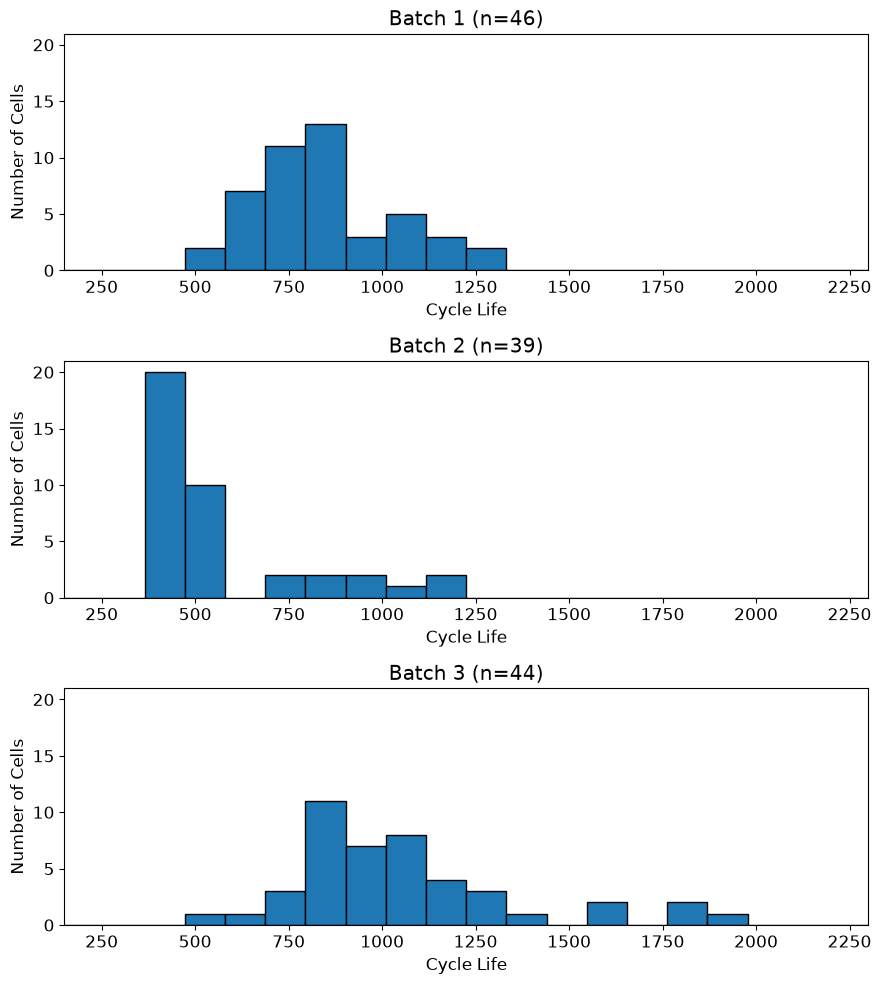

배치별 장·중·단수명 비율 (%): 보고서 표 4


,total_cells,short_count,middle_count,long_count,short_pct,long_pct,middle_pct
batch,,,,,,,
Batch 1,46,0,36,10,0.0,21.7,78.3
Batch 2,39,28,8,3,71.8,7.7,20.5
Batch 3,44,0,21,23,0.0,52.3,47.7



단수명 셀 목록


,batch,cell_id,cycle_life
65,Batch 2,19,392.0
52,Batch 2,6,393.0
61,Batch 2,15,396.0
67,Batch 2,21,408.0
76,Batch 2,30,412.0
51,Batch 2,5,416.0
48,Batch 2,2,424.0
77,Batch 2,31,425.0
60,Batch 2,14,426.0
74,Batch 2,28,437.0


수명이 짧은 상위 5셀: 보고서 표 5


,batch,cell_id,cycle_life
65,Batch 2,19,392.0
52,Batch 2,6,393.0
61,Batch 2,15,396.0
67,Batch 2,21,408.0
76,Batch 2,30,412.0


150~2300 범위 밖 셀 수: 0


In [58]:
df_life_valid = df_life.dropna(subset=["cycle_life"]).copy()

# 배치별 수명 분포
bins = np.linspace(150, 2300, 21)
fig, axes = plt.subplots(
    3, 1, figsize=(9, 10), sharex=True, sharey=True
)

for ax, batch_name in zip(axes, batch_files):
    life = df_life_valid.loc[
        df_life_valid["batch"] == batch_name, "cycle_life"
    ]
    ax.hist(life, bins=bins, edgecolor="black")
    ax.set_title(f"{batch_name} (n={len(life)})")
    ax.set_xlabel("Cycle Life")
    ax.set_ylabel("Number of Cells")
    ax.tick_params(labelbottom=True)
    ax.set_xlim(150, 2300)

axes[0].set_ylabel("Number of Cells")
plt.tight_layout()
plt.show()

# 장·단수명 개수와 비율: 수명이 확인된 셀 기준
life_ratio = df_life_valid.groupby("batch")["cycle_life"].agg(
    total_cells="size",
    short_count=lambda s: (s < 500).sum(),
    middle_count=lambda s: s.between(500, 1000).sum(),
    long_count=lambda s: (s > 1000).sum(),
)

life_ratio["short_pct"] = (
    life_ratio["short_count"] / life_ratio["total_cells"] * 100
)
life_ratio["long_pct"] = (
    life_ratio["long_count"] / life_ratio["total_cells"] * 100
)

life_ratio["middle_pct"] = life_ratio["middle_count"] / life_ratio["total_cells"] * 100

print("배치별 장·중·단수명 비율 (%): 보고서 표 4")
display(life_ratio.round(1))

# 수명이 짧은 셀 목록
short_cells = df_life_valid.loc[
    df_life_valid["cycle_life"] < 500,
    ["batch", "cell_id", "cycle_life"],
].sort_values(["batch", "cycle_life"])

print("\n단수명 셀 목록")
display(short_cells)
print("수명이 짧은 상위 5셀: 보고서 표 5")
display(short_cells.head(5))

# 히스토그램 범위 밖 셀 확인
outside_range = df_life_valid.loc[
    ~df_life_valid["cycle_life"].between(150, 2300)
]
print("150~2300 범위 밖 셀 수:", len(outside_range))

### 해석

- Batch 1은 약 600~900사이클 부근에 집중되어 있으며, 장수명 비율은 21.7%, 단수명 비율은 0%이다.
- Batch 2는 약 400~500사이클 부근에 집중되어 있다. 단수명 비율은 71.8%로 가장 높고, 장수명 비율은 7.7%이다.
- Batch 3는 긴 수명 방향으로 꼬리가 늘어지는 분포를 보이며, 장수명 비율은 52.3%로 가장 높다.
- 중간수명(500~1,000사이클, 경계 포함) 비율은 Batch 1에서 78.3%, Batch 2에서 20.5%, Batch 3에서 47.7%이다. Batch 1은 중간수명, Batch 2는 단수명 셀이 가장 큰 비중을 차지한다.
- 수명이 확인된 셀 중 150~2,300사이클 범위 밖의 셀은 없다.
- 가장 짧은 셀은 Batch 2의 cell_id=19로, 수명은 392사이클이다. Batch 2에서 단수명 셀이 다수 관측되므로, 짧은 수명만으로 데이터 오류나 이상치라고 단정하지 않는다. 충전 프로토콜과 열화 곡선을 비교하여 원인 가설을 검토한다.
- 수명 결측인 Batch 2의 8개 셀과 Batch 3의 2개 셀은 수명 분포·비율 계산에서 제외했다. 따라서 결과는 수명이 확인된 셀을 대상으로 한 비교이다.

## 2. 방전 용량 열화 곡선

배치별 방전 용량 추이와 대표 셀의 곡선을 비교하여 열화 속도 변화와 knee 후보 구간을 탐색한다.

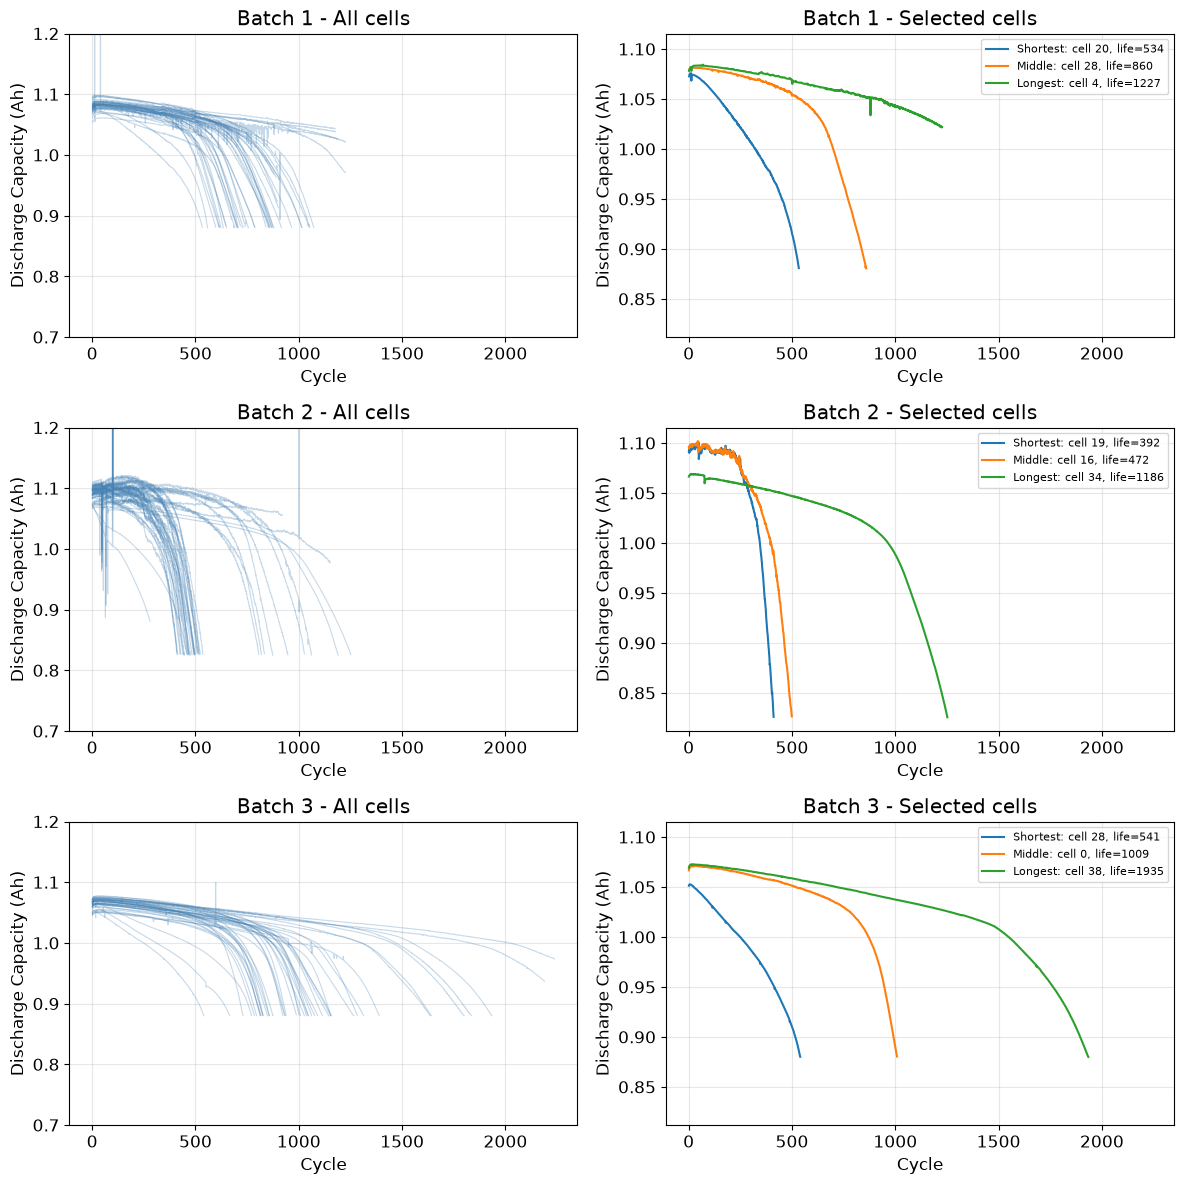

대표 셀: 보고서 표 6 (Middle은 수명 중간 순위 셀)


,batch,selection,cell_id,cycle_life
0,Batch 1,Shortest,20,534.0
1,Batch 1,Middle,28,860.0
2,Batch 1,Longest,4,1227.0
3,Batch 2,Shortest,19,392.0
4,Batch 2,Middle,16,472.0
5,Batch 2,Longest,34,1186.0
6,Batch 3,Shortest,28,541.0
7,Batch 3,Middle,0,1009.0
8,Batch 3,Longest,38,1935.0


In [59]:
# 세 배치의 사이클 번호와 방전 용량 읽기
curves = {}

for batch_name, filename in batch_files.items():
    with h5py.File(os.path.join(DATA_DIR, filename), "r") as f:
        summary_refs = f["batch"]["summary"][()].ravel()

        for i, ref in enumerate(summary_refs):
            summary = f[ref]

            cycle = np.asarray(summary["cycle"][()]).ravel()
            qd = np.asarray(summary["QDischarge"][()]).ravel()

            assert len(cycle) == len(qd), \
                f"{batch_name}, cell {i}: 배열 길이가 다릅니다."

            # 첫 사이클의 주요 측정값이 모두 0인 기록 확인
            empty_initial = (cycle == 1) & (qd == 0)

            for key in [
                "QCharge", "IR", "Tmax", "Tavg", "Tmin", "chargetime"
            ]:
                values = np.asarray(summary[key][()]).ravel()
                assert len(values) == len(cycle)
                empty_initial &= values == 0

            valid = (
                np.isfinite(cycle)
                & np.isfinite(qd)
                & ~empty_initial
            )

            curves[(batch_name, i)] = (cycle[valid], qd[valid])

# 보고서 그림 2: 배치별 행, 왼쪽 전체 셀 / 오른쪽 대표 셀
fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True, sharey="col")
representative_records = []

for row, batch_name in enumerate(batch_files):
    for (name, cell_id), (cycle, qd) in curves.items():
        if name == batch_name:
            axes[row, 0].plot(cycle, qd, color="steelblue", alpha=0.3, linewidth=0.8)
    axes[row, 0].set_title(f"{batch_name} - All cells")
    axes[row, 0].set_ylim(0.7, 1.2)  # 표시 범위만 제한하며 원자료는 삭제하지 않음

    ranked = df_life_valid.loc[df_life_valid["batch"] == batch_name].sort_values(
        ["cycle_life", "cell_id"]
    )
    for position, label in zip(
        [0, len(ranked) // 2, len(ranked) - 1], ["Shortest", "Middle", "Longest"]
    ):
        cell = ranked.iloc[position]
        cell_id = int(cell["cell_id"])
        cycle, qd = curves[(batch_name, cell_id)]
        axes[row, 1].plot(
            cycle, qd, linewidth=1.5,
            label=f"{label}: cell {cell_id}, life={cell['cycle_life']:.0f}"
        )
        representative_records.append({
            "batch": batch_name, "selection": label,
            "cell_id": cell_id, "cycle_life": cell["cycle_life"],
        })
    axes[row, 1].set_title(f"{batch_name} - Selected cells")
    axes[row, 1].legend(fontsize=8)
    for ax in axes[row]:
        ax.set_xlabel("Cycle")
        ax.set_ylabel("Discharge Capacity (Ah)")
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
df_representatives = pd.DataFrame(representative_records)
print("대표 셀: 보고서 표 6 (Middle은 수명 중간 순위 셀)")
display(df_representatives)


### 분석 결과

각 행은 하나의 배치이며, 왼쪽은 전체 셀, 오른쪽은 수명 순위로 선택한 대표 셀이다. 대표 셀 표의 `Middle`은 중간 순위 셀로, 배치의 평균 곡선이나 정확한 수명 중앙값을 의미하지 않는다.

- Batch 1은 셀마다 용량 감소 시점이 다르며, 일부 셀에서 후기 열화가 가속된다.
- Batch 2는 많은 셀에서 비교적 이른 사이클에 급격한 용량 감소가 나타난다.
- Batch 3는 방전 용량을 더 오랫동안 유지하는 셀이 많지만, 후기에는 감소가 가속되는 곡선도 관찰된다.
- 여러 대표 셀에서 완만한 감소 이후 기울기가 급해져, 열화 속도가 일정하지 않음을 확인했다. 이 전환 구간을 knee 후보로 볼 수 있으나, 자동 검출이나 정확한 발생 시점 계산은 수행하지 않았다.
- Batch 1의 최장수명 대표 셀(cell_id=4, 제공 수명 1,227사이클)은 관측 끝에서도 Qd가 약 1.02 Ah이며 뚜렷한 knee가 보이지 않는다. 제공된 수명과 EOL 도달 여부의 관계는 추가 확인이 필요하다.

전체 셀 그래프의 y축은 비교를 위해 0.7~1.2 Ah로 제한했으며, 원본 데이터는 유지했다.

## 3. 초기 사이클의 ΔQ(V) 비교

100번째와 10번째 사이클의 방전 용량 차이를 계산하고, 장·단수명 셀의 곡선을 비교한다. 곡선의 평균, 최솟값, 분산과 로그 분산을 후보 피처로 추출한다.

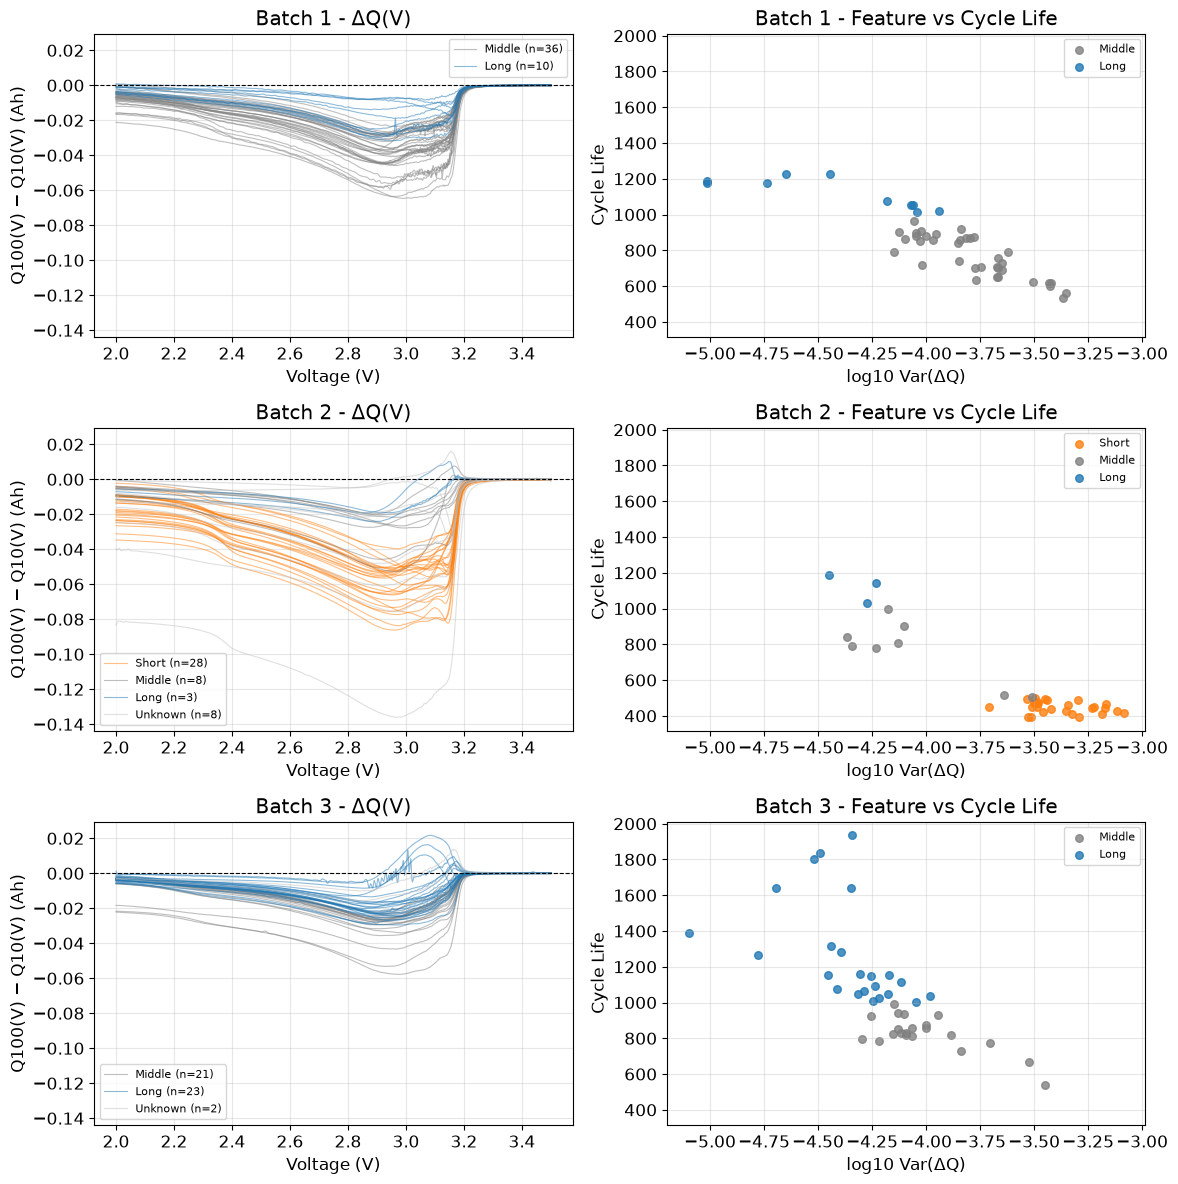

배치·수명 그룹별 피처 요약


n_cells  median_mean  median_min  median_var  \
batch   life_group                                                 
Batch 1 Long             10    -0.009265   -0.022070    0.000051   
        Middle           36    -0.017209   -0.038294    0.000164   
Batch 2 Long              3    -0.008120   -0.019165    0.000053   
        Middle            8    -0.011181   -0.027066    0.000070   
        Short            28    -0.028665   -0.056180    0.000358   
        Unknown           8    -0.019312   -0.042156    0.000156   
Batch 3 Long             23    -0.008693   -0.020147    0.000048   
        Middle           21    -0.011765   -0.027646    0.000081   
        Unknown           2    -0.005033   -0.012865    0.000025   

                    median_log_var  
batch   life_group                  
Batch 1 Long             -4.310746  
        Middle           -3.786476  
Batch 2 Long             -4.271782  
        Middle           -4.153341  
        Short            -3.446103  
        Unknown          -3.907459  
Batch 3 Long             -4.316748  
        Middle           -4.091804  
        Unknown          -4.608571

ΔQ 계산에서 제외된 셀 수: 0


In [60]:
delta_curves = {}
feature_records = []
skipped = []

for batch_name, filename in batch_files.items():
    with h5py.File(os.path.join(DATA_DIR, filename), "r") as f:
        batch_group = f["batch"]
        cycle_refs = batch_group["cycles"][()].ravel()
        summary_refs = batch_group["summary"][()].ravel()
        voltage_refs = batch_group["Vdlin"][()].ravel()

        for cell_id, cycle_ref in enumerate(cycle_refs):
            cycles_group = f[cycle_ref]
            q_refs = cycles_group["Qdlin"][()].ravel()

            summary = f[summary_refs[cell_id]]
            cycle_numbers = np.asarray(summary["cycle"][()]).ravel()

            # 실제 사이클 번호로 10번째와 100번째 기록 찾기
            idx10 = np.flatnonzero(cycle_numbers == 10)
            idx100 = np.flatnonzero(cycle_numbers == 100)

            if (
                len(q_refs) != len(cycle_numbers)
                or len(idx10) != 1
                or len(idx100) != 1
            ):
                skipped.append({
                    "batch": batch_name,
                    "cell_id": cell_id,
                    "reason": "사이클 번호 또는 기록 수 확인 필요",
                })
                continue

            ref10 = q_refs[idx10[0]]
            ref100 = q_refs[idx100[0]]
            vref = voltage_refs[cell_id]

            if not ref10 or not ref100 or not vref:
                skipped.append({
                    "batch": batch_name,
                    "cell_id": cell_id,
                    "reason": "Qdlin 또는 전압축 참조 없음",
                })
                continue

            voltage = np.asarray(f[vref][()], dtype=float).ravel()
            q10 = np.asarray(f[ref10][()], dtype=float).ravel()
            q100 = np.asarray(f[ref100][()], dtype=float).ravel()

            if not (len(voltage) == len(q10) == len(q100) > 1):
                skipped.append({
                    "batch": batch_name,
                    "cell_id": cell_id,
                    "reason": "전압축과 Qdlin 길이 불일치",
                })
                continue

            if not (
                np.isfinite(voltage).all()
                and np.isfinite(q10).all()
                and np.isfinite(q100).all()
            ):
                skipped.append({
                    "batch": batch_name,
                    "cell_id": cell_id,
                    "reason": "전압 또는 Qdlin에 결측/무한값 존재",
                })
                continue

            # 전압 오름차순으로 동일하게 정렬
            order = np.argsort(voltage)
            voltage = voltage[order]
            delta_q = (q100 - q10)[order]

            if not np.all(np.diff(voltage) > 0):
                skipped.append({
                    "batch": batch_name,
                    "cell_id": cell_id,
                    "reason": "전압축에 중복값 존재",
                })
                continue

            delta_var = np.var(delta_q, ddof=0)

            delta_curves[(batch_name, cell_id)] = (voltage, delta_q)
            feature_records.append({
                "batch": batch_name,
                "cell_id": cell_id,
                "delta_q_mean": np.mean(delta_q),
                "delta_q_min": np.min(delta_q),
                "delta_q_var": delta_var,
                "delta_q_log_var": (
                    np.log10(delta_var) if delta_var > 0 else np.nan
                ),
            })

df_delta = pd.DataFrame(feature_records).merge(
    df_life,
    on=["batch", "cell_id"],
    how="left",
    validate="one_to_one",
)

# 앞서 사용한 DAY1 장·단수명 기준
df_delta["life_group"] = np.select(
    [
        df_delta["cycle_life"].isna(),
        df_delta["cycle_life"] < 500,
        df_delta["cycle_life"] > 1000,
    ],
    ["Unknown", "Short", "Long"],
    default="Middle",
)

group_colors = {
    "Short": "tab:orange",
    "Middle": "gray",
    "Long": "tab:blue",
    "Unknown": "silver",
}

# 보고서 그림 3: 왼쪽 ΔQ 곡선 / 오른쪽 로그 분산과 수명
fig, axes = plt.subplots(
    3, 2, figsize=(12, 12), sharex="col", sharey="col"
)

for row, batch_name in enumerate(batch_files):
    batch_df = df_delta.loc[df_delta["batch"] == batch_name]

    for group, color in group_colors.items():
        group_df = batch_df.loc[batch_df["life_group"] == group]

        # ΔQ(V) 곡선
        for j, record in enumerate(group_df.itertuples(index=False)):
            voltage, delta_q = delta_curves[(batch_name, record.cell_id)]

            axes[row, 0].plot(
                voltage,
                delta_q,
                color=color,
                alpha=0.5,
                linewidth=0.8,
                label=f"{group} (n={len(group_df)})" if j == 0 else None,
            )

        # 로그 분산과 수명의 관계
        known = group_df.dropna(
            subset=["cycle_life", "delta_q_log_var"]
        )
        if not known.empty:
            axes[row, 1].scatter(
                known["delta_q_log_var"],
                known["cycle_life"],
                color=color,
                alpha=0.8,
                s=30,
                label=group,
            )

    axes[row, 0].axhline(0, color="black", linestyle="--", linewidth=0.8)
    axes[row, 0].set_title(f"{batch_name} - ΔQ(V)")
    axes[row, 0].set_xlabel("Voltage (V)")
    axes[row, 0].legend(fontsize=8)

    axes[row, 1].set_title(f"{batch_name} - Feature vs Cycle Life")
    axes[row, 1].set_xlabel("log10 Var(ΔQ)")
    axes[row, 1].legend(fontsize=8)

    axes[row, 0].set_ylabel("Q100(V) − Q10(V) (Ah)")
    axes[row, 1].set_ylabel("Cycle Life")
    for ax in axes[row]:
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.grid(alpha=0.3)


plt.tight_layout()
plt.show()

print("배치·수명 그룹별 피처 요약")
display(
    df_delta.groupby(["batch", "life_group"]).agg(
        n_cells=("cell_id", "count"),
        median_mean=("delta_q_mean", "median"),
        median_min=("delta_q_min", "median"),
        median_var=("delta_q_var", "median"),
        median_log_var=("delta_q_log_var", "median"),
    )
)

print("ΔQ 계산에서 제외된 셀 수:", len(skipped))
if skipped:
    display(pd.DataFrame(skipped))

### 분석 결과

왼쪽은 전압별 ΔQ 곡선, 오른쪽은 셀별 ΔQ 로그 분산과 수명의 관계이다.

- 대부분의 셀에서 약 2.7~3.1 V 구간의 ΔQ가 음수로 나타나며, 초기 10~100사이클 사이에도 방전 용량 곡선의 변화가 관찰된다.
- Batch 2의 단수명 셀은 장수명 셀보다 ΔQ가 더 크게 음수로 내려간다. ΔQ 최솟값의 중앙값은 단수명 그룹에서 약 -0.056 Ah, 장수명 그룹에서 약 -0.019 Ah이다.
- 세 배치 모두 로그 분산이 작을수록 수명이 긴 경향을 보인다. Batch 1의 로그 분산 중앙값은 장수명 그룹 -4.31, 중간수명 그룹 -3.79이며, Batch 3에서도 각각 -4.32와 -4.09로 같은 경향이 나타난다.
- 따라서 ΔQ의 평균·최솟값·분산 및 로그 분산은 초기 곡선의 변화와 전압별 차이를 요약하는 후보 피처로 활용할 수 있다. 다만 그룹 간 겹침이 있어 단일 피처만으로 수명을 완전히 구분하기는 어렵다.
- Batch 1·3에는 단수명 셀이 없고, Batch 2의 장수명 셀은 3개뿐이므로 그룹 비교에는 표본 구성의 한계가 있다.

ΔQ 계산에서 제외된 셀은 없으며, 수명이 결측인 셀은 곡선 비교에는 포함하고 수명과의 관계 해석에서는 제외했다. 이 피처는 100번째 사이클까지 필요하므로 초기 5사이클 분류 모델에는 사용할 수 없다.

## 4. 충전 조건과 수명의 관계

충전 프로토콜별 평균 수명과 표본 수를 비교한다. 1·2단계 C-rate 및 전환 SOC와 수명, 초기 10~100사이클의 용량 감소율 사이의 관계를 분석한다.

충전 프로토콜별 요약


,batch,protocol,total_cells,known_life,mean_life,median_life,known_fade_rate,mean_fade_rate
10,Batch 1,5.4C(80%)-5.4C,2,2,546.500,546.5,2,0.130
22,Batch 1,8C(35%)-3.6C,2,2,607.500,607.5,2,0.034
18,Batch 1,7C(40%)-3.6C,2,2,621.000,621.0,2,0.018
19,Batch 1,7C(40%)-3C,2,2,676.000,676.0,2,0.021
21,Batch 1,8C(25%)-3.6C,2,2,676.500,676.5,2,0.020
17,Batch 1,7C(30%)-3.6C,2,2,722.500,722.5,2,0.011
9,Batch 1,5.4C(70%)-3C,2,2,739.500,739.5,2,0.043
16,Batch 1,6C(60%)-3C,2,2,744.000,744.0,2,0.028
2,Batch 1,4.8C(80%)-4.8C,2,2,753.000,753.0,2,0.024
14,Batch 1,6C(50%)-3.6C,2,2,792.500,792.5,2,0.033


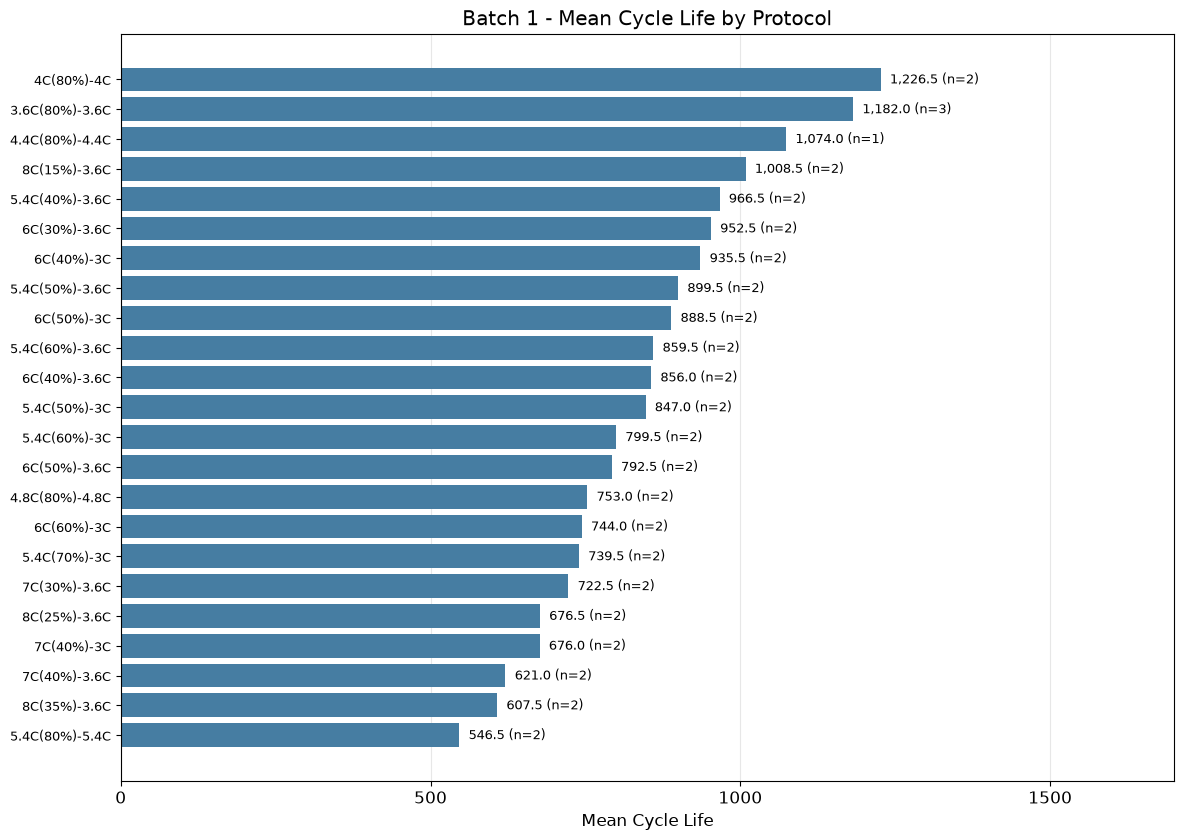

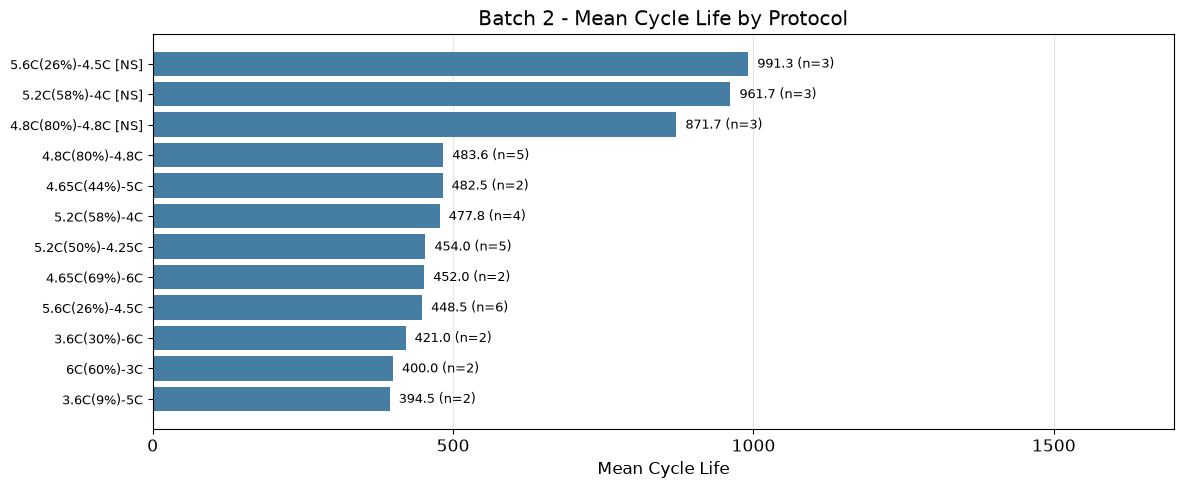

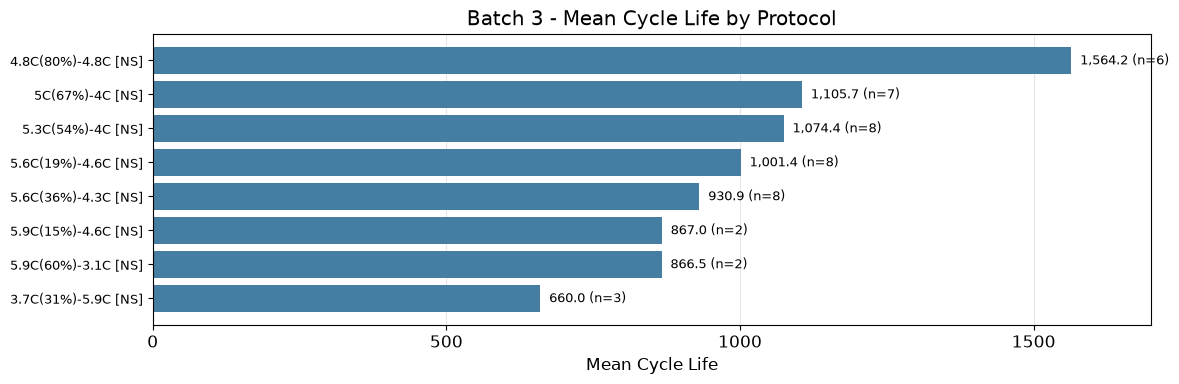

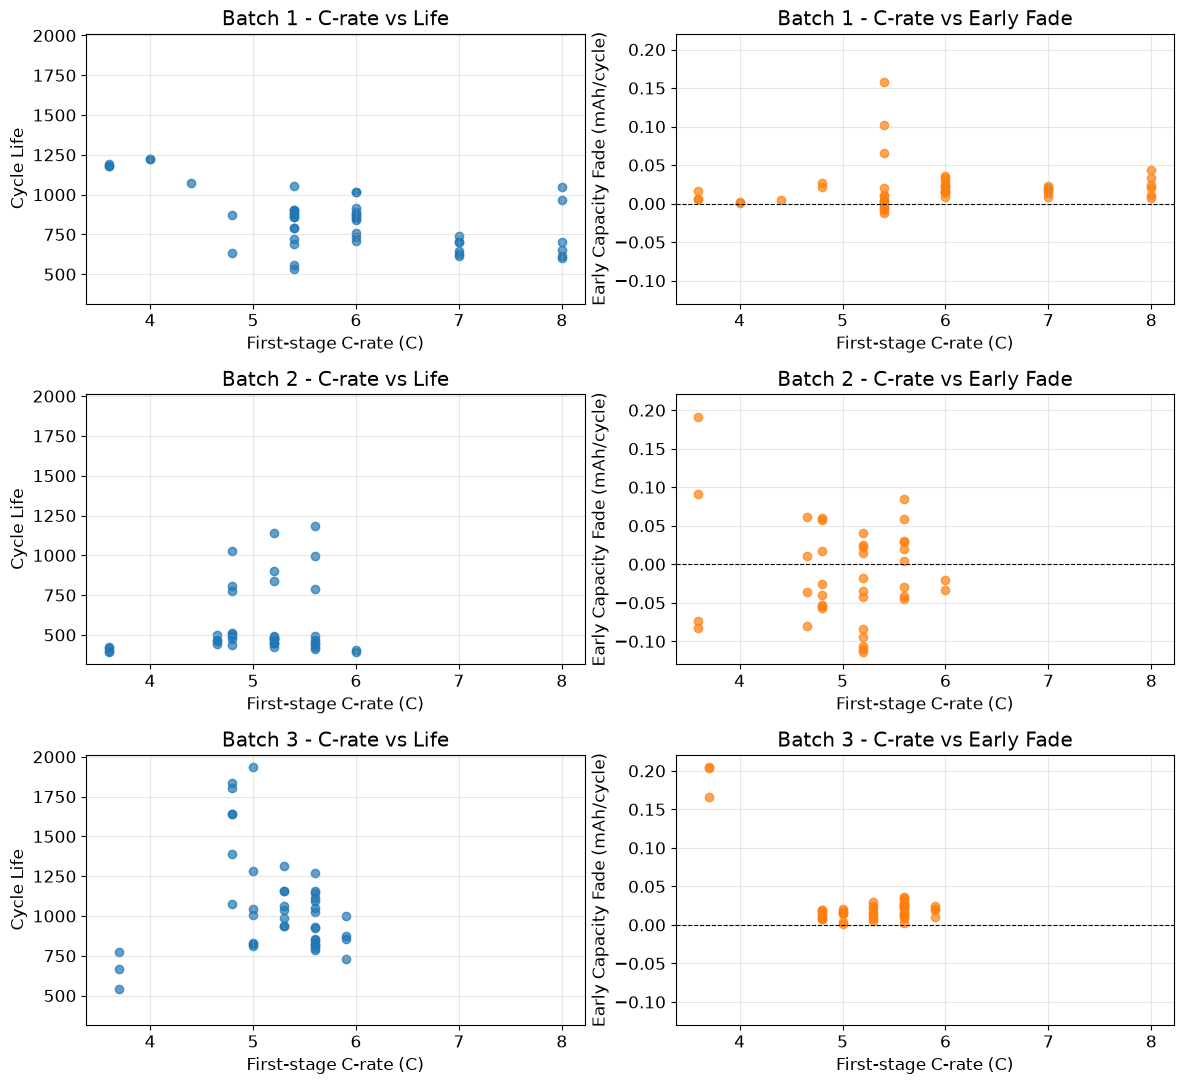

충전 조건과 수명·초기 감소율의 상관


,batch,feature,target,n_pairs,spearman_rho
0,Batch 1,charge_c1,cycle_life,46,-0.483
1,Batch 1,charge_c1,early_fade_rate,46,0.372
2,Batch 1,charge_c2,cycle_life,46,0.047
3,Batch 1,charge_c2,early_fade_rate,46,0.110
4,Batch 1,switch_soc,cycle_life,46,0.185
5,Batch 1,switch_soc,early_fade_rate,46,-0.089
6,Batch 2,charge_c1,cycle_life,39,0.055
7,Batch 2,charge_c1,early_fade_rate,39,0.046
8,Batch 2,charge_c2,cycle_life,39,-0.119
9,Batch 2,charge_c2,early_fade_rate,39,0.173


충전 설정 추출 실패 셀 수: 8


,batch,cell_id,protocol
68,Batch 2,22,VarCharge-2C-100cycles
69,Batch 2,23,VarCharge-4C-100cycles
81,Batch 2,35,VarCharge-6C-100cycles
82,Batch 2,36,VarCharge-8C-100cycles
83,Batch 2,37,3.6C(80%)-3.6C(SLOWCYCLE
84,Batch 2,38,4.8C(80%)-4.8C(SLOWCYCLE
85,Batch 2,39,3.6C(9%)-5C(SLOWCYCLE
86,Batch 2,40,5.2C(58%)-4C(SLOWCYCLE


초기 감소율 계산 불가 셀 수: 0
충전 설정의 상관 요약: 보고서 표 9


...

,protocol,total_cells,known_life,mean_life,median_life,mean_fade_rate
3,4C(80%)-4C,2,2,1226.5,1226.5,0.001
0,3.6C(80%)-3.6C,3,3,1182.0,1179.0,0.009
1,4.4C(80%)-4.4C,1,1,1074.0,1074.0,0.005
20,8C(15%)-3.6C,2,2,1008.5,1008.5,0.016
4,5.4C(40%)-3.6C,2,2,966.5,966.5,0.003
11,6C(30%)-3.6C,2,2,952.5,952.5,0.018
13,6C(40%)-3C,2,2,935.5,935.5,0.012
5,5.4C(50%)-3.6C,2,2,899.5,899.5,0.007
15,6C(50%)-3C,2,2,888.5,888.5,0.015
7,5.4C(60%)-3.6C,2,2,859.5,859.5,-0.003


Batch 2: 프로토콜 전체 요약


,protocol,total_cells,known_life,mean_life,median_life,mean_fade_rate
37,5.6C(26%)-4.5C-newstructure,3,3,991.3,997.0,0.039
35,5.2C(58%)-4C-newstructure,3,3,961.7,904.0,0.030
31,4.8C(80%)-4.8C-newstructure,3,3,871.7,809.0,0.022
29,4.8C(80%)-4.8C,5,5,483.6,492.0,-0.032
27,4.65C(44%)-5C,2,2,482.5,482.5,-0.059
33,5.2C(58%)-4C,4,4,477.8,483.0,-0.052
32,5.2C(50%)-4.25C,5,5,454.0,449.0,-0.076
28,4.65C(69%)-6C,2,2,452.0,452.0,0.036
36,5.6C(26%)-4.5C,6,6,448.5,446.0,-0.001
23,3.6C(30%)-6C,2,2,421.0,421.0,0.141


Batch 3: 프로토콜 전체 요약


,protocol,total_cells,known_life,mean_life,median_life,mean_fade_rate
44,4.8C(80%)-4.8C-newstructure,8,6,1564.2,1640.0,0.013
50,5C(67%)-4C-newstructure,7,7,1105.7,1009.0,0.013
45,5.3C(54%)-4C-newstructure,8,8,1074.4,1051.0,0.016
46,5.6C(19%)-4.6C-newstructure,8,8,1001.4,1038.0,0.023
47,5.6C(36%)-4.3C-newstructure,8,8,930.9,890.5,0.020
48,5.9C(15%)-4.6C-newstructure,2,2,867.0,867.0,0.015
49,5.9C(60%)-3.1C-newstructure,2,2,866.5,866.5,0.023
43,3.7C(31%)-5.9C-newstructure,3,3,660.0,667.0,0.191


In [61]:
charge_records = []

for batch_name, filename in batch_files.items():
    with h5py.File(os.path.join(DATA_DIR, filename), "r") as f:
        policy_refs = f["batch"]["policy_readable"][()].ravel()

        for cell_id, ref in enumerate(policy_refs):
            # MATLAB 문자 배열을 문자열로 변환
            if ref:
                codes = np.asarray(f[ref][()], dtype="<u2").ravel()
                protocol = codes.tobytes().decode("utf-16le").strip("\x00 ")
            else:
                protocol = None

            cycle, qd = curves[(batch_name, cell_id)]
            early_mask = (cycle >= 10) & (cycle <= 100)

            x = cycle[early_mask]
            y = qd[early_mask]

            # 튀는 값의 영향을 줄이는 중앙값 기반 기울기
            if (
                len(np.unique(x)) >= 3
                and np.any(x == 10)
                and np.any(x == 100)
            ):
                slope = theilslopes(y, x)[0]
                early_fade_rate = -1000 * slope  # mAh/cycle
            else:
                early_fade_rate = np.nan

            charge_records.append({
                "batch": batch_name,
                "cell_id": cell_id,
                "protocol": protocol,
                "early_fade_rate": early_fade_rate,
            })

df_charge = pd.DataFrame(charge_records).merge(
    df_life,
    on=["batch", "cell_id"],
    how="left",
    validate="one_to_one",
)

# 예: 5.6C(26%)-4.5C
# Batch 3의 -newstructure 등 추가 표기도 보존
number = r"\d+(?:\.\d+)?"
pattern = (
    rf"^({number})C\(({number})%\)-({number})C(?:-(.*))?$"
)

parsed = (
    df_charge["protocol"]
    .str.replace(" ", "", regex=False)
    .str.extract(pattern)
)
parsed.columns = ["charge_c1", "switch_soc", "charge_c2", "protocol_note"]

for column in ["charge_c1", "charge_c2", "switch_soc"]:
    df_charge[column] = pd.to_numeric(parsed[column], errors="coerce")

df_charge["protocol_note"] = parsed["protocol_note"]

# 프로토콜별 수명과 초기 감소율 요약
protocol_summary = (
    df_charge.groupby(["batch", "protocol"], dropna=False)
    .agg(
        total_cells=("cell_id", "size"),
        known_life=("cycle_life", "count"),
        mean_life=("cycle_life", "mean"),
        median_life=("cycle_life", "median"),
        known_fade_rate=("early_fade_rate", "count"),
        mean_fade_rate=("early_fade_rate", "mean"),
    )
    .reset_index()
)

print("충전 프로토콜별 요약")
display(
    protocol_summary
    .sort_values(["batch", "mean_life"])
    .round(3)
)

# 보고서 그림 4~6: 배치별 독립 그림, 평균과 수명 유효 n을 막대 끝에 표시
# [NS]는 원본 -newstructure 접미사의 표시용 약칭이다.
for batch_name in batch_files:
    sub = (
        protocol_summary.loc[protocol_summary["batch"] == batch_name]
        .dropna(subset=["mean_life"])
        .sort_values("mean_life", ascending=False, kind="stable")
    )
    fig, ax = plt.subplots(figsize=(12, max(4, 0.32 * len(sub) + 1.2)))
    positions = np.arange(len(sub))
    labels = sub["protocol"].str.replace("-newstructure", " [NS]", regex=False)
    ax.barh(positions, sub["mean_life"], color="#467da2")
    ax.set_yticks(positions, labels=labels, fontsize=9)
    ax.invert_yaxis()
    for y, record in zip(positions, sub.itertuples(index=False)):
        ax.text(
            record.mean_life + 15, y,
            f"{record.mean_life:,.1f} (n={record.known_life})",
            va="center", fontsize=9, clip_on=False,
        )
    ax.set_xlim(0, 1700)
    ax.set_xticks([0, 500, 1000, 1500])
    ax.set_title(f"{batch_name} - Mean Cycle Life by Protocol")
    ax.set_xlabel("Mean Cycle Life")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

# 보고서 그림 7: 왼쪽 C1과 수명 / 오른쪽 C1과 초기 감소율
fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True, sharey="col")
for row, batch_name in enumerate(batch_files):
    sub = df_charge.loc[df_charge["batch"] == batch_name]
    life_data = sub.dropna(subset=["charge_c1", "cycle_life"])
    fade_data = sub.dropna(subset=["charge_c1", "early_fade_rate"])
    axes[row, 0].scatter(life_data["charge_c1"], life_data["cycle_life"], color="tab:blue", alpha=0.7)
    axes[row, 0].set_title(f"{batch_name} - C-rate vs Life")
    axes[row, 0].set_ylabel("Cycle Life")
    axes[row, 1].scatter(fade_data["charge_c1"], fade_data["early_fade_rate"], color="tab:orange", alpha=0.7)
    axes[row, 1].axhline(0, color="black", linestyle="--", linewidth=0.8)
    axes[row, 1].set_title(f"{batch_name} - C-rate vs Early Fade")
    axes[row, 1].set_ylabel("Early Capacity Fade (mAh/cycle)")
    for ax in axes[row]:
        ax.set_xlabel("First-stage C-rate (C)")
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 충전 패턴과 수명·초기 감소율의 Spearman 상관
correlation_records = []

for batch_name in batch_files:
    sub = df_charge.loc[df_charge["batch"] == batch_name]

    for feature in ["charge_c1", "charge_c2", "switch_soc"]:
        for target in ["cycle_life", "early_fade_rate"]:
            pairs = sub[[feature, target]].dropna()

            if (
                len(pairs) >= 3
                and pairs[feature].nunique() > 1
                and pairs[target].nunique() > 1
            ):
                rho = pairs.corr(method="spearman").iloc[0, 1]
            else:
                rho = np.nan

            correlation_records.append({
                "batch": batch_name,
                "feature": feature,
                "target": target,
                "n_pairs": len(pairs),
                "spearman_rho": rho,
            })

df_charge_corr = pd.DataFrame(correlation_records)

print("충전 조건과 수명·초기 감소율의 상관")
display(df_charge_corr.round(3))

# 해석에 필요한 누락 확인
unparsed = df_charge[
    ["charge_c1", "charge_c2", "switch_soc"]
].isna().any(axis=1)

print("충전 설정 추출 실패 셀 수:", unparsed.sum())
if unparsed.any():
    display(
        df_charge.loc[unparsed, ["batch", "cell_id", "protocol"]]
    )

print(
    "초기 감소율 계산 불가 셀 수:",
    df_charge["early_fade_rate"].isna().sum(),
)
# 보고서 표 9와 같은 열 구성: 수명/감소율 상관과 각각의 유효 n
charge_corr_report = df_charge_corr.pivot(
    index=["batch", "feature"], columns="target", values=["spearman_rho", "n_pairs"]
)
print("충전 설정의 상관 요약: 보고서 표 9")
display(charge_corr_report.round(3))

# 부록 A1~A3: 수명 결측 프로토콜도 보존한다.
for batch_name in batch_files:
    print(f"{batch_name}: 프로토콜 전체 요약")
    display(
        protocol_summary.loc[protocol_summary["batch"] == batch_name]
        .sort_values("mean_life", ascending=False, kind="stable", na_position="last")
        [["protocol", "total_cells", "known_life", "mean_life", "median_life", "mean_fade_rate"]]
        .round({"mean_life": 1, "median_life": 1, "mean_fade_rate": 3})
    )


### 분석 결과

프로토콜별 막대는 평균 수명이 긴 순서로 정렬했다. 막대 끝의 숫자는 평균 수명과 수명이 확인된 셀 수 `n`이며, `[NS]`는 원본의 `-newstructure` 표기를 줄인 것이다.

- 충전 프로토콜에 따라 평균 수명에 차이가 나타났다. Batch 1에서 `4C(80%)-4C`의 평균 수명은 1,226.5사이클, `5.4C(80%)-5.4C`는 546.5사이클이었다. 다만 두 프로토콜 모두 표본이 2개여서 일반화에는 주의가 필요하다.
- Batch 1에서는 1단계 C-rate가 높을수록 수명이 짧아지는 경향(ρ=-0.483)과 초기 용량 감소율이 커지는 경향(ρ=0.372)이 관찰됐다. 그러나 수명과의 관계는 Batch 2에서 거의 없었고(ρ=0.055), Batch 3에서도 약했다(ρ=-0.229). 따라서 높은 C-rate가 항상 짧은 수명으로 이어진다고 단정하기 어렵다.
- 동일한 초기 C-rate에서도 전환 SOC에 따라 수명이 달랐다. Batch 1의 `8C(15%)-3.6C`와 `8C(35%)-3.6C`의 평균 수명은 각각 1,008.5와 607.5사이클이었다. 초기 C-rate뿐 아니라 후기 C-rate와 전환 시점을 함께 고려할 필요가 있다.
- Batch 3에서는 전환 SOC가 높을수록 수명이 길고(ρ=0.443), 초기 용량 감소율이 작은 경향(ρ=-0.427)이 나타났다. 이는 이번 표본에서 관찰된 관계이며 인과 효과를 의미하지 않는다.
- Batch 2의 `5.6C(26%)-4.5C` 평균 수명은 448.5사이클(n=6), 같은 설정에 `newstructure`가 붙은 그룹은 991.3사이클(n=3)이었다. 추가 표기에 해당하는 실제 실험 조건은 미확인이므로, 수명 차이를 C-rate만으로 설명하기 어렵다.
- Batch 3의 `4.8C(80%)-4.8C [NS]`는 평균 수명이 1,564.2사이클로 해당 배치에서 가장 높았다. 전체 8셀 중 수명이 확인된 6셀의 평균이며, 소표본과 다른 충전 조건의 영향을 고려하면 최적 프로토콜이라고 확정할 수 없다.
- 일부 셀의 초기 감소율은 음수로, 초기 10~100사이클에서 용량이 증가했음을 뜻한다. 초기 감소율을 전체 수명 구간의 열화 속도와 동일하게 해석해서는 안 된다.

충전 패턴을 요약하는 1·2단계 C-rate와 전환 SOC를 후보 피처로 검토할 수 있다. 다만 프로토콜별 표본 수와 배치별 관계 차이를 고려해야 한다.

Batch 2의 특수 프로토콜 8개는 현재 규칙으로 충전 설정을 추출하지 못해 설정 상관 분석에서 제외했다. 초기 감소율 자체는 모든 셀에서 계산됐으며, 이번 분석은 실제 전류 파형이 아닌 프로토콜 설정을 기준으로 수행했다.

## 5. 초기 피처와 수명의 상관관계

초기 100사이클 내에서 추출한 셀별 피처와 수명의 상관관계를 비교한다. Batch 1에서 가장 강한 관계를 식별하고, 멀티클리니어리티 문제를 확인한다. 

Batch 1: 수명과의 상관 순위


,feature,n_pairs,pearson_r,spearman_rho
8,delta_q_log_var,46,-0.886,-0.871
7,delta_q_min,46,0.882,0.850
6,delta_q_mean,46,0.854,0.828
5,chargetime_median,46,0.745,0.638
1,qd_change_100_10,46,0.550,0.613
9,early_fade_rate,46,-0.510,-0.586
10,charge_c1,46,-0.580,-0.483
3,tavg_median,46,-0.499,-0.380
4,tmax_median,46,-0.412,-0.321
2,ir_median,46,0.336,0.281


Batch 1에서 가장 강한 Spearman 관계: delta_q_log_var (ρ=-0.871)
배치별 Spearman 상관과 유효 표본 수


spearman_rho                 n_pairs                
batch                  Batch 1 Batch 2 Batch 3 Batch 1 Batch 2 Batch 3
feature                                                               
delta_q_log_var         -0.871  -0.709  -0.797    46.0    39.0    44.0
delta_q_min              0.850   0.661   0.776    46.0    39.0    44.0
delta_q_mean             0.828   0.697   0.756    46.0    39.0    44.0
chargetime_median        0.638  -0.809   0.264    46.0    39.0    44.0
qd_change_100_10         0.613  -0.055   0.032    46.0    39.0    44.0
early_fade_rate         -0.586   0.220  -0.132    46.0    39.0    44.0
charge_c1               -0.483   0.055  -0.229    46.0    39.0    44.0
tavg_median             -0.380   0.172   0.023    46.0    39.0    44.0
tmax_median             -0.321  -0.140  -0.049    46.0    39.0    44.0
ir_median                0.281  -0.344   0.171    46.0    39.0    44.0
switch_soc               0.185   0.288   0.443    46.0    39.0    44.0
qd_10                    0.100   0.077   0.130    46.0    39.0    44.0
charge_c2                0.047  -0.119   0.016    46.0    39.0    44.0

수명과의 상관: 보고서 표 10


batch,Batch 1 Pearson,Batch 1 Spearman,Batch 2 Spearman,Batch 3 Spearman
feature,,,,
delta_q_log_var,-0.886,-0.871,-0.709,-0.797
delta_q_min,0.882,0.850,0.661,0.776
delta_q_mean,0.854,0.828,0.697,0.756
chargetime_median,0.745,0.638,-0.809,0.264
qd_change_100_10,0.550,0.613,-0.055,0.032
early_fade_rate,-0.510,-0.586,0.220,-0.132
charge_c1,-0.580,-0.483,0.055,-0.229
tavg_median,-0.499,-0.380,0.172,0.023
tmax_median,-0.412,-0.321,-0.140,-0.049


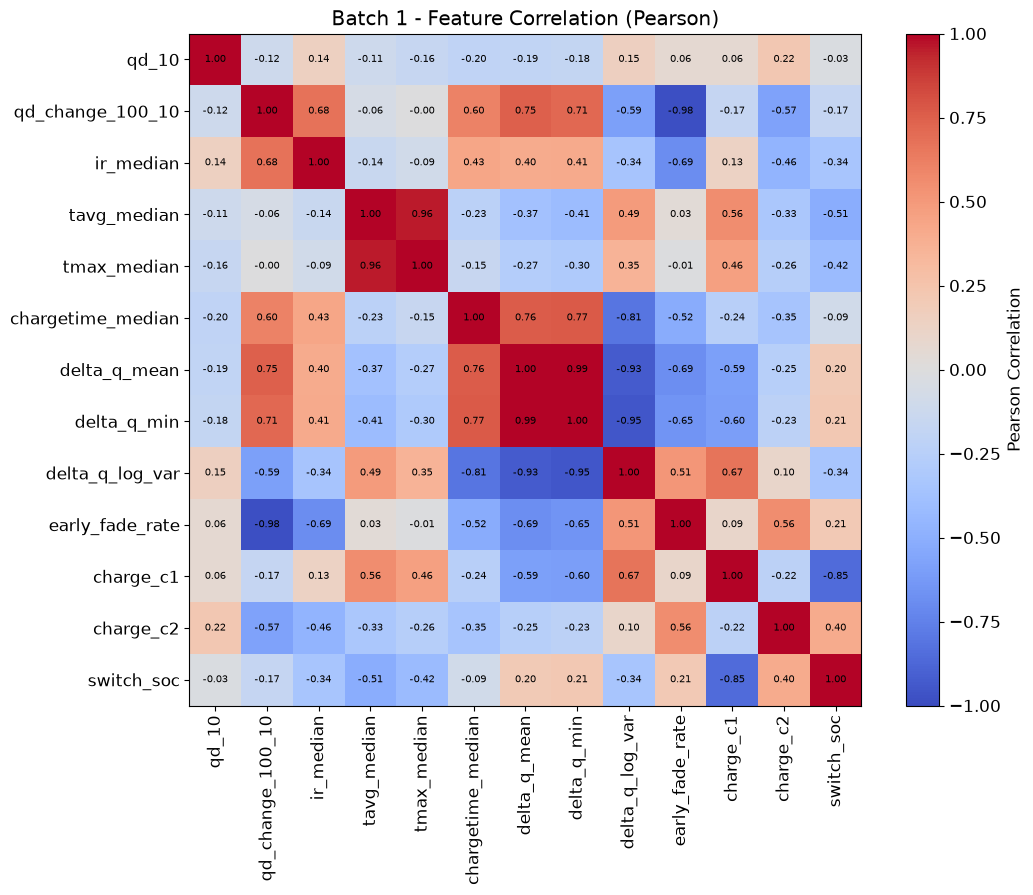

Batch 1: |Pearson r| ≥ 0.9인 피처 쌍


,feature_1,feature_2,pearson_r,n_pairs
2,delta_q_mean,delta_q_min,0.993,46
0,qd_change_100_10,early_fade_rate,-0.979,46
1,tavg_median,tmax_median,0.960,46
4,delta_q_min,delta_q_log_var,-0.947,46
3,delta_q_mean,delta_q_log_var,-0.926,46


VIF 계산에 사용한 Batch 1 셀 수: 46
상수 또는 유효값 부족으로 제외한 피처: []
Batch 1: VIF


,feature,VIF
7,delta_q_min,154.64
6,delta_q_mean,117.71
1,qd_change_100_10,49.12
9,early_fade_rate,42.68
3,tavg_median,42.24
8,delta_q_log_var,38.06
4,tmax_median,30.83
10,charge_c1,16.22
12,switch_soc,12.53
5,chargetime_median,7.58


In [62]:
summary_records = []

for batch_name, filename in batch_files.items():
    with h5py.File(os.path.join(DATA_DIR, filename), "r") as f:
        summary_refs = f["batch"]["summary"][()].ravel()

        for cell_id, ref in enumerate(summary_refs):
            summary = f[ref]
            cycle = np.asarray(summary["cycle"][()]).ravel()
            qd = np.asarray(summary["QDischarge"][()]).ravel()

            assert len(cycle) == len(qd)

            idx10 = np.flatnonzero(cycle == 10)
            idx100 = np.flatnonzero(cycle == 100)

            qd10 = qd[idx10[0]] if len(idx10) == 1 else np.nan
            qd100 = qd[idx100[0]] if len(idx100) == 1 else np.nan

            record = {
                "batch": batch_name,
                "cell_id": cell_id,
                "qd_10": qd10,
                "qd_change_100_10": qd100 - qd10,
            }

            # 初期 10~100사이클의 대표 측정값
            early_mask = (cycle >= 10) & (cycle <= 100)

            for source, feature in {
                "IR": "ir_median",
                "Tavg": "tavg_median",
                "Tmax": "tmax_median",
                "chargetime": "chargetime_median",
            }.items():
                values = np.asarray(summary[source][()]).ravel()
                assert len(values) == len(cycle)

                selected = values[early_mask & np.isfinite(values)]
                record[feature] = (
                    np.median(selected) if len(selected) else np.nan
                )

            summary_records.append(record)

# 셀별 피처 결합: 타깃과 식별자는 입력 피처에서 제외
keys = ["batch", "cell_id"]

df_features = (
    df_life
    .merge(
        pd.DataFrame(summary_records),
        on=keys,
        how="left",
        validate="one_to_one",
    )
    .merge(
        df_delta[
            keys + ["delta_q_mean", "delta_q_min", "delta_q_log_var"]
        ],
        on=keys,
        how="left",
        validate="one_to_one",
    )
    .merge(
        df_charge[
            keys + [
                "early_fade_rate",
                "charge_c1",
                "charge_c2",
                "switch_soc",
            ]
        ],
        on=keys,
        how="left",
        validate="one_to_one",
    )
)

feature_cols = [
    "qd_10",
    "qd_change_100_10",
    "ir_median",
    "tavg_median",
    "tmax_median",
    "chargetime_median",
    "delta_q_mean",
    "delta_q_min",
    "delta_q_log_var",
    "early_fade_rate",
    "charge_c1",
    "charge_c2",
    "switch_soc",
]

df_features[feature_cols] = df_features[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

# 배치별 피처-수명 상관
corr_records = []

for batch_name in batch_files:
    sub = df_features.loc[df_features["batch"] == batch_name]

    for feature in feature_cols:
        pairs = sub[[feature, "cycle_life"]].dropna()

        if (
            len(pairs) >= 3
            and pairs[feature].nunique() > 1
            and pairs["cycle_life"].nunique() > 1
        ):
            pearson = pairs[feature].corr(
                pairs["cycle_life"], method="pearson"
            )
            spearman = pairs[feature].corr(
                pairs["cycle_life"], method="spearman"
            )
        else:
            pearson = spearman = np.nan

        corr_records.append({
            "batch": batch_name,
            "feature": feature,
            "n_pairs": len(pairs),
            "pearson_r": pearson,
            "spearman_rho": spearman,
        })

df_feature_corr = pd.DataFrame(corr_records)

# Batch 1의 관계 강도를 기준으로 표시 순서 정하기
ranking = (
    df_feature_corr.loc[
        df_feature_corr["batch"] == "Batch 1"
    ]
    .assign(abs_rho=lambda x: x["spearman_rho"].abs())
    .sort_values("abs_rho", ascending=False)
)

feature_order = ranking["feature"].tolist()

print("Batch 1: 수명과의 상관 순위")
display(
    ranking[
        ["feature", "n_pairs", "pearson_r", "spearman_rho"]
    ].round(3)
)

valid_ranking = ranking.dropna(subset=["spearman_rho"])
if not valid_ranking.empty:
    strongest = valid_ranking.iloc[0]
    print(
        "Batch 1에서 가장 강한 Spearman 관계:",
        strongest["feature"],
        f"(ρ={strongest['spearman_rho']:.3f})",
    )

print("배치별 Spearman 상관과 유효 표본 수")
display(
    df_feature_corr.pivot(
        index="feature",
        columns="batch",
        values=["spearman_rho", "n_pairs"],
    )
    .reindex(feature_order)
    .round(3)
)

# 보고서 표 10: 기존 막대그래프와 같은 상관값을 통합 표로 표시
correlation_report = (
    df_feature_corr.pivot(index="feature", columns="batch", values="spearman_rho")
    .reindex(feature_order)
    .rename(columns=lambda name: f"{name} Spearman")
)
correlation_report.insert(
    0, "Batch 1 Pearson", ranking.set_index("feature")["pearson_r"]
)
print("수명과의 상관: 보고서 표 10")
display(correlation_report.round(3))

# 다중공선성 진단은 Batch 1에서 수행
batch1_features = df_features.loc[
    df_features["batch"] == "Batch 1", feature_cols
]

active_cols = [
    column for column in feature_cols
    if batch1_features[column].nunique(dropna=True) > 1
]
constant_cols = [
    column for column in feature_cols if column not in active_cols
]

feature_corr = batch1_features[active_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(feature_corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(
    range(len(active_cols)),
    labels=active_cols,
    rotation=90,
)
ax.set_yticks(range(len(active_cols)), labels=active_cols)

for i in range(len(active_cols)):
    for j in range(len(active_cols)):
        value = feature_corr.iloc[i, j]
        if np.isfinite(value):
            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center", fontsize=7,
            )

ax.set_title("Batch 1 - Feature Correlation (Pearson)")
fig.colorbar(im, ax=ax, label="Pearson Correlation")
plt.tight_layout()
plt.show()

# 절댓값 0.9 이상인 피처 쌍 표시
high_corr_pairs = []

for i, first in enumerate(active_cols):
    for second in active_cols[i + 1:]:
        value = feature_corr.loc[first, second]

        if np.isfinite(value) and abs(value) >= 0.9:
            high_corr_pairs.append({
                "feature_1": first,
                "feature_2": second,
                "pearson_r": value,
                "n_pairs": len(
                    batch1_features[[first, second]].dropna()
                ),
            })

print("Batch 1: |Pearson r| ≥ 0.9인 피처 쌍")
if high_corr_pairs:
    display(
        pd.DataFrame(high_corr_pairs)
        .assign(abs_r=lambda x: x["pearson_r"].abs())
        .sort_values("abs_r", ascending=False)
        .drop(columns="abs_r")
        .round(3)
    )
else:
    print("해당 피처 쌍 없음")

# VIF: 한 피처를 나머지 피처들이 얼마나 설명하는지 확인
# 진단용 계산이며 모델 전처리에 재사용하지 않음
vif_input = batch1_features[active_cols].dropna()

# 완전 관측 행만 남긴 후에도 변동이 있는 열 사용
vif_cols = [
    column for column in active_cols
    if vif_input[column].nunique() > 1
]
vif_input = vif_input[vif_cols]

print("VIF 계산에 사용한 Batch 1 셀 수:", len(vif_input))
print("상수 또는 유효값 부족으로 제외한 피처:", constant_cols)

if len(vif_cols) >= 2 and len(vif_input) > len(vif_cols) + 1:
    x = vif_input.to_numpy(dtype=float)
    x = (x - x.mean(axis=0)) / x.std(axis=0, ddof=0)

    vif_records = []

    for j, feature in enumerate(vif_cols):
        y = x[:, j]
        others = np.delete(x, j, axis=1)
        design = np.column_stack([np.ones(len(x)), others])

        coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
        residual = y - design @ coefficients

        rss = np.sum(residual ** 2)
        tss = np.sum((y - y.mean()) ** 2)

        vif = np.inf if rss <= 1e-12 * tss else tss / rss

        vif_records.append({"feature": feature, "VIF": vif})

    df_vif = pd.DataFrame(vif_records).sort_values(
        "VIF", ascending=False
    )

    print("Batch 1: VIF")
    display(df_vif.round(2))
else:
    print("VIF 계산에 필요한 표본 또는 변동 피처가 부족함")

### 분석 결과

- Batch 1에서 수명과 가장 강한 관계를 보인 피처는 ΔQ 로그 분산이었다(Pearson r=-0.886, Spearman ρ=-0.871). 로그 분산이 작을수록 수명이 긴 경향이 나타났다.
- ΔQ 로그 분산은 Batch 2·3에서도 각각 ρ=-0.709, -0.797로 같은 방향의 관계를 보였다. ΔQ 평균과 최솟값도 세 배치에서 양의 상관을 보여, 초기 곡선의 변화가 수명 예측의 주요 후보 신호임을 확인했다.
- 10번째 사이클의 방전 용량 자체는 수명과의 관계가 약했다(세 배치에서 ρ=0.077~0.130). 초기 용량의 절댓값보다 사이클 사이의 변화와 전압별 차이를 요약하는 피처가 더 강한 관계를 보였다.
- 충전 시간은 Batch 1에서 양의 관계(ρ=0.638), Batch 2에서 음의 관계(ρ=-0.809)를 보였다. Batch 2에서는 충전 시간의 절대 상관이 ΔQ 로그 분산보다 크므로, 로그 분산이 모든 배치에서 가장 강한 피처라고 해석하지 않는다. 일부 피처의 관계는 배치마다 달라, 한 배치에서 관찰된 관계를 그대로 일반화하기 어렵다.

### 다중공선성과 모델 설계 시사점

- ΔQ 평균과 최솟값(r=0.993), 용량 변화량과 초기 감소율(r=-0.979), 평균 온도와 최고 온도(r=0.960)는 서로 높은 상관을 보였다.
- ΔQ 최솟값과 평균의 VIF는 각각 154.64, 117.71로 높았으며, 여러 피처에서 다중공선성이 나타났다. 이들을 함께 사용하는 선형 모델에서는 계수 추정과 해석이 불안정해질 수 있다.
- 따라서 ΔQ 통계, 용량 감소, 온도처럼 정보가 겹치는 피처군에서 대표 피처를 선택하거나 규제 모델을 검토할 필요가 있다. 높은 VIF만으로 유용한 피처를 자동 제거하지 않고, 최종 조합은 Batch 1 내부 검증으로 결정한다.

상관관계는 인과관계나 실제 예측 성능을 의미하지 않는다. 수명과의 상관 분석에는 수명이 확인된 Batch 1·2·3의 46·39·44개 셀을 사용했다.

## 배치 비교 종합

셀 수·수명 비율·초기 피처의 상관을 함께 비교한다. 수명 관련 통계에서는 결측 타깃을 제외한다.


In [63]:
# 보고서 표 2: 원본 셀 수와 수명 유효/결측 수
report_sample_counts = df_life.groupby("batch")["cycle_life"].agg(
    total_cells="size", available_life="count"
)
report_sample_counts["missing_life"] = report_sample_counts["total_cells"] - report_sample_counts["available_life"]
report_sample_counts.loc["Total"] = report_sample_counts.sum()
display(report_sample_counts)

# 보고서 표 13의 수치 요약. 모두 셀별 한 행을 기준으로 한다.
report_batch_summary = df_life.groupby("batch")["cycle_life"].median().to_frame("median_life")
report_batch_summary = report_batch_summary.join(life_ratio[["short_pct", "long_pct"]])
for feature in ["delta_q_log_var", "chargetime_median"]:
    report_batch_summary[f"{feature}_rho"] = (
        df_feature_corr.loc[df_feature_corr["feature"] == feature]
        .set_index("batch")["spearman_rho"]
    )
print("배치별 핵심 차이: 보고서 표 13")
display(report_batch_summary.round({
    "median_life": 1, "short_pct": 1, "long_pct": 1,
    "delta_q_log_var_rho": 3, "chargetime_median_rho": 3,
}))


,total_cells,available_life,missing_life
batch,,,
Batch 1,46,46,0
Batch 2,47,39,8
Batch 3,46,44,2
Total,139,129,10


배치별 핵심 차이: 보고서 표 13


,median_life,short_pct,long_pct,delta_q_log_var_rho,chargetime_median_rho
batch,,,,,
Batch 1,858.5,0.0,21.7,-0.871,0.638
Batch 2,472.0,71.8,7.7,-0.709,-0.809
Batch 3,1005.5,0.0,52.3,-0.797,0.264


## 후보 피처 정의

아래는 추출한 후보의 정의이며 최종 선택 목록은 아니다.

| 피처 | 정의 | 관측 범위 | 단위 |
|---|---|---|---|
| qd_10 | 10사이클의 방전 용량 | 10 | Ah |
| qd_change_100_10 | Qd100 − Qd10 | 10·100 | Ah |
| ir_median | IR의 중앙값 | 10–100 | 원자료 저항 단위 |
| tavg_median / tmax_median | 평균 / 최고 온도의 중앙값 | 10–100 | °C |
| chargetime_median | 충전 시간의 중앙값 | 10–100 | 원자료 시간 단위 |
| delta_q_mean / delta_q_min | 전압별 ΔQ의 평균 / 최솟값 | 10·100 | Ah |
| delta_q_log_var | log10 Var(ΔQ), ddof=0; 분산이 0이면 NaN | 10·100 | Ah² 수치의 log10 |
| early_fade_rate | −1000 × Theil–Sen(Qd 대 cycle) 기울기 | 10–100 | mAh/cycle |
| charge_c1 / charge_c2 | 1·2단계 충전 설정 | 프로토콜 | C |
| switch_soc | 충전 전류 전환 SOC | 프로토콜 | % |

IR·충전 시간의 물리 단위는 DAY2 전 확인한다. 셀별 중앙값은 유한한 관측만 사용했다. 실제 I(t) 파형이나 자동 knee 검출을 수행한 것은 아니다.


## 모델 설계 전략

### 1. 피처 엔지니어링

초기 100사이클 이내의 데이터를 셀별 한 행으로 요약한다. EDA에서 확인한 관계와 피처 간 중복을 바탕으로 다음 후보를 검토한다.

| 후보 피처 | 선택 근거 및 사용 전략 |
|---|---|
| ΔQ 로그 분산 | Batch 1에서 수명과 가장 강한 관계를 보여 기준 모델의 핵심 후보로 검토한다. |
| 방전 용량 변화량 | 초기 용량 변화를 요약한다. 초기 감소율과 높은 상관이 있으므로 둘 중 하나를 검토한다. |
| 평균 온도 중앙값 | 초기 열적 상태를 요약한다. 최고 온도와 정보가 겹쳐 대표 온도 피처 하나를 검토한다. |
| 충전 시간 중앙값 | Batch 1에서 수명과 관계가 나타나 추가 효과를 검토한다. |
| 내부 저항·충전 설정 | 추가 후보로 두고 내부 검증에서 성능 개선 여부를 확인한다. |

ΔQ 평균·최솟값·로그 분산은 서로 높은 상관을 보였으므로 모두 함께 사용하는 것을 기본으로 삼지 않는다. 먼저 로그 분산 단독 모델을 만들고, 보조 피처를 추가했을 때의 효과를 비교한다.

### 2. 태스크와 타깃 선정

회귀를 선택하여 초기 100사이클의 데이터로 총 수명인 `cycle_life`를 예측한다.

현재 EDA에서 ΔQ100−10 피처가 수명과 강한 관계를 보였으며, 연속적인 수명 차이를 예측하려는 목적에 적합하다. 초기 5사이클 분류를 선택하면 피처를 해당 관측 범위에 맞게 다시 정의해야 한다.

학습에서는 `log10(cycle_life)`를 예측하는 방식을 검토한다. 예측 결과는 사이클 단위로 역변환하여 평가한다.

### 3. 데이터 처리와 후보 모델

- 첫 사이클의 주요 측정값이 모두 0인 빈 기록을 제외한다.
- 수명이 결측인 셀의 타깃은 대체하지 않는다. 평가 가능한 셀 수와 제외 사유를 기록한다.
- 셀 ID, 배치명, 전체 수명 길이와 후기 knee 시점은 입력 피처로 사용하지 않는다.
- 결측치 대치와 표준화는 학습 데이터 또는 각 CV 학습 폴드에서만 수행한다.

후보 모델은 다음과 같다.

| 모델 | 검토 이유 |
|---|---|
| ΔQ 로그 분산 단독 선형 회귀 | 핵심 피처 하나의 예측력을 확인하는 기준 모델 |
| Ridge | 피처 간 높은 상관을 고려한 규제 선형 모델 |
| Elastic Net | 규제와 피처 선택을 함께 검토할 수 있는 모델 |

학습 셀 수가 적고 다중공선성이 확인됐으므로, 소수의 피처와 규제 선형 모델부터 비교한다. 최종 모델은 실험 전 확정하지 않는다.

### 4. 검증과 평가

Batch 1에서 충전 프로토콜 그룹을 고려해 내부 학습·검증 데이터를 분리한다. 학습 부분에서는 그룹 기반 교차검증으로 피처 조합과 하이퍼파라미터를 선택하고, 별도 검증 데이터에서 성능을 확인한다.

설정을 확정한 뒤 Batch 2에서 최종 평가한다. Batch 2의 모델 성능을 보고 다시 튜닝하지 않는다. 무작위 분할에는 seed 42를 사용한다.

주 지표는 MAPE(%), 보조 지표는 RMSE(사이클)로 설정한다. 두 지표 모두 로그 예측을 사이클 단위로 역변환한 후 계산한다.

모델링 전에는 제공된 cycle_life의 정의와 배치 간 동일 셀 연결 여부를 확인한다. 논문의 전처리·분할과 이번 과제 조건이 다르므로, 과제에서 제시한 9.1%는 참고 목표로 비교한다.

### 5. EDA와 검증 계획의 연결

현재 단계는 후보 피처 추출과 후보 모델 설계까지이며, 학습·최종 피처 선택·성능 평가는 아직 수행하지 않았다.

| EDA 시사점 | 설계 및 검증 계획 |
|---|---|
| Batch 1에서 ΔQ 로그 분산의 수명 관계가 가장 강함 | 단일 피처 선형 회귀를 기준 후보로 두고 MAPE·RMSE 비교 |
| ΔQ 통계, 용량 변화·감소율, 평균·최고 온도의 중복 | 묶음별 대표 피처 및 Ridge·Elastic Net을 같은 내부 분할에서 비교 |
| 충전 시간 등의 상관이 배치별로 반전 | 보조 피처의 추가 효과는 Batch 1 내부 검증에서 판단 |
| 학습 셀이 46개이며 배치 간 분포가 다름 | 소수 피처와 작은 모델부터 비교하고 폴드 간 변동 확인 |

프로토콜 약 20%를 hold-out으로 두고 나머지에서 그룹 기반 3-fold CV를 수행하는 방안을 검토한다. 이는 미실행 예시 계획이며 실제 그룹 수와 타깃 분포를 확인한 뒤 정한다. 최종 설정을 고정한 후 Batch 1 전체로 재학습하고 Batch 2를 평가한다. 과제 성능표의 Train에는 단순 적합 점수가 아닌 내부 CV 결과를 기록할 계획이다.

소표본의 셀별 요약 데이터이므로 딥러닝은 우선 후보에서 제외한다. 과제에 따라 Batch 2·3의 타깃 기반 EDA는 이미 관찰했으므로 완전히 미관찰인 test와 동등하다고 주장하지 않는다. Batch 3의 DAY2 추가 평가는 생략한다. 모델 학습 전에 EOL 정의·동일 물리 셀 연결·제외 규칙을 확인하며, 현재 총 cycle_life 예측과 잔여수명 예측을 구분한다.
